# Tokyo 2020 Olympics – Data Analysis

Analysis of the Tokyo 2020 Olympic Games (held in 2021): data cleaning and merging of six datasets, the relation between a country's GDP and its medals, regression and classification of national success, a hypothesis test on gender balance, a time-series analysis of 120 years of Olympic history, a small retrieval-augmented question-answering assistant (Gemini) and a quiz built from web-scraped facts.

**Data** (see the README for download links): `Athletes.xlsx`, `Coaches.xlsx`, `EntriesGender.xlsx`, `Medals.xlsx`, `Teams.xlsx` (Tokyo 2020), `API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512.csv` (World Bank GDP by country and year, 1960–2025) and `athlete_events.csv` (Olympic history 1896–2016). Put the files into a `Datasets/` folder next to this notebook. In Colab they are read from Google Drive; if Drive cannot be mounted, upload the `Datasets` ZIP to `/content` and the notebook unpacks it.

# Loading the data

In [3]:
import os
import glob
import zipfile

# The notebook looks for the data in this order:
#  1. Colab + Google Drive: the Datasets folder in Drive (DRIVE_DIR)
#  2. Colab without Drive: the files or a ZIP of them uploaded from the computer
#     (Files panel on the left, or the upload dialog this cell opens if nothing is found)
#  3. Locally: a Datasets/ or data/ folder next to the notebook
DRIVE_DIR = '/content/drive/MyDrive/Colab Notebooks/1.semestar/Projekti/OI_2021/Datasets'
CONTENT_DIR = '/content'

GDP_FILE = 'API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512.csv'
REQUIRED_FILES = ['Medals.xlsx', 'Teams.xlsx', 'Athletes.xlsx', 'Coaches.xlsx',
                  'EntriesGender.xlsx', GDP_FILE, 'athlete_events.csv']

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.isdir(DRIVE_DIR):
    try:
        drive.mount('/content/drive')
    except Exception as e:
        # "credential propagation was unsuccessful": the Drive permission pop-up was
        # closed, blocked, or approved with a different Google account.
        print(f"Google Drive could not be mounted ({e}). Looking for uploaded files instead.")


def find_data_dir():
    """Return the first folder that contains Medals.xlsx, unpacking an uploaded ZIP if needed."""
    def search():
        for folder in [DRIVE_DIR, 'Datasets', 'data', os.path.join(CONTENT_DIR, 'Datasets'), CONTENT_DIR]:
            if os.path.exists(os.path.join(folder, 'Medals.xlsx')):
                return folder
        # files inside one or two extra folder levels, e.g. a ZIP that unpacked to Datasets/Datasets
        for pattern in ['*/Medals.xlsx', '*/*/Medals.xlsx']:
            hits = sorted(glob.glob(os.path.join(CONTENT_DIR, pattern)) + glob.glob(pattern))
            if hits:
                return os.path.dirname(hits[0])
        return None

    folder = search()
    if folder is None:
        zips = {os.path.abspath(z) for z in glob.glob(os.path.join(CONTENT_DIR, '*.zip')) + glob.glob('*.zip')}
        for zip_path in sorted(zips):
            with zipfile.ZipFile(zip_path) as zf:
                if any(name.endswith('Medals.xlsx') for name in zf.namelist()):
                    zf.extractall(os.path.dirname(os.path.abspath(zip_path)))
                    print(f"Unpacked {os.path.basename(zip_path)}")
        folder = search()
    return folder


DATA_DIR = find_data_dir()
if DATA_DIR is None and IN_COLAB:
    # Nothing found: open an upload dialog for the ZIP or the seven files from the computer.
    # Uploaded files are saved to /content (the folder shown in the Files panel).
    from google.colab import files
    print("Data not found. Choose the Datasets ZIP or the seven data files on your computer:")
    uploaded = files.upload()
    print("Uploaded:", ", ".join(uploaded) if uploaded else "nothing")
    DATA_DIR = find_data_dir()
if DATA_DIR is None:
    raise FileNotFoundError(
        "The data files were not found. In Colab, run this cell again and upload the Datasets ZIP "
        "or the seven files; locally, put them into ./Datasets. "
        f"Required files: {', '.join(REQUIRED_FILES)}"
    )


def data_path(name):
    return os.path.join(DATA_DIR, name)


missing = [f for f in REQUIRED_FILES if not os.path.exists(data_path(f))]
print("Data folder:", DATA_DIR)
print("Missing files:", missing if missing else "none")

Google Drive could not be mounted (Error: credential propagation was unsuccessful). Looking for uploaded files instead.
Data folder: /content
Missing files: none


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import warnings

# The Kaggle .xlsx files have no default cell style; openpyxl warns about it but reads them correctly
warnings.filterwarnings("ignore", message="Workbook contains no default style", category=UserWarning)

medals = pd.read_excel(data_path('Medals.xlsx'))                 # country ranking by medals
teams = pd.read_excel(data_path('Teams.xlsx'))                   # teams by discipline and event
athletes = pd.read_excel(data_path('Athletes.xlsx'))             # athletes (name, country, discipline)
coaches = pd.read_excel(data_path('Coaches.xlsx'))               # coaches by discipline
entries_gender = pd.read_excel(data_path('EntriesGender.xlsx'))  # female, male and total entries per discipline
gdp_data = pd.read_csv(data_path(GDP_FILE), skiprows=4)          # World Bank GDP (first 4 lines are metadata)

In [6]:
medals.head()

,Rank,Team/NOC,Gold,Silver,Bronze,Total,Rank by Total
0,1,United States of America,39,41,33,113,1
1,2,People's Republic of China,38,32,18,88,2
2,3,Japan,27,14,17,58,5
3,4,Great Britain,22,21,22,65,4
4,5,ROC,20,28,23,71,3


In [7]:
teams.head()

,Name,Discipline,NOC,Event
0,Belgium,3x3 Basketball,Belgium,Men
1,China,3x3 Basketball,People's Republic of China,Men
2,China,3x3 Basketball,People's Republic of China,Women
3,France,3x3 Basketball,France,Women
4,Italy,3x3 Basketball,Italy,Women


In [8]:
athletes.head()

,Name,NOC,Discipline
0,AALERUD Katrine,Norway,Cycling Road
1,ABAD Nestor,Spain,Artistic Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing
3,ABALDE Alberto,Spain,Basketball
4,ABALDE Tamara,Spain,Basketball


In [9]:
coaches.head()

,Name,NOC,Discipline,Event
0,ABDELMAGID Wael,Egypt,Football,NaN
1,ABE Junya,Japan,Volleyball,NaN
2,ABE Katsuhiko,Japan,Basketball,NaN
3,ADAMA Cherif,Côte d'Ivoire,Football,NaN
4,AGEBA Yuya,Japan,Volleyball,NaN


In [10]:
entries_gender.head()

,Discipline,Female,Male,Total
0,3x3 Basketball,32,32,64
1,Archery,64,64,128
2,Artistic Gymnastics,98,98,196
3,Artistic Swimming,105,0,105
4,Athletics,969,1072,2041


In [11]:
gdp_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.092428e+09,3.276188e+09,3.347562e+09,2.461056e+09,2.889305e+09,3.326671e+09,3.746573e+09,4.167588e+09,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,2.420573e+10,2.495893e+10,2.707328e+10,3.176919e+10,3.027960e+10,3.380623e+10,...,9.792406e+11,1.021972e+12,1.019354e+12,9.385461e+11,1.113060e+12,1.226461e+12,1.179122e+12,1.252564e+12,1.358694e+12,NaN
2,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.875346e+10,1.805322e+10,1.879944e+10,1.995593e+10,1.426000e+10,1.449724e+10,1.715223e+10,1.777851e+10,NaN,NaN
3,Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,1.190481e+10,1.270772e+10,1.363059e+10,1.446891e+10,1.580356e+10,1.692088e+10,...,6.942064e+11,7.778058e+11,1.026528e+12,9.636882e+11,1.026670e+12,1.063748e+12,9.384807e+11,7.373670e+11,8.525270e+11,NaN
4,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,8.562960e+10,9.050606e+10,8.119381e+10,5.851203e+10,7.828392e+10,1.282340e+11,1.060423e+11,1.030805e+11,1.221749e+11,NaN


In [12]:
datasets = {
    "Athletes": athletes,
    "Coaches": coaches,
    "Entries Gender": entries_gender,
    "GDP Data": gdp_data,
    "Medals": medals,
    "Teams": teams
}

print("Missing values in all datasets:\n")

for name, dataset in datasets.items():
    print(f"Missing values in dataset '{name}':")
    print(dataset.isnull().sum())
    print("-" * 50)

Missing values in all datasets:

Missing values in dataset 'Athletes':
Name          0
NOC           0
Discipline    0
dtype: int64
--------------------------------------------------
Missing values in dataset 'Coaches':
Name            0
NOC             0
Discipline      0
Event         145
dtype: int64
--------------------------------------------------
Missing values in dataset 'Entries Gender':
Discipline    0
Female        0
Male          0
Total         0
dtype: int64
--------------------------------------------------
Missing values in dataset 'GDP Data':
Country Name        0
Country Code        0
Indicator Name      0
Indicator Code      0
1960              114
                 ... 
2022                9
2023               14
2024               18
2025               32
Unnamed: 70       266
Length: 71, dtype: int64
--------------------------------------------------
Missing values in dataset 'Medals':
Rank             0
Team/NOC         0
Gold             0
Silver           0
Bron

**All files were loaded. Observations:**

**Athletes.xlsx:** athletes (name, NOC – National Olympic Committee, discipline). No missing values.

**Coaches.xlsx:** name, NOC, discipline and event. The "Event" column has many missing values.

**EntriesGender.xlsx:** number of female, male and total entries per discipline. No missing values.

**GDP (World Bank):** GDP of countries and regions for 1960–2025, with many gaps in the time series.

**Medals.xlsx:** team ranking by medals. No missing values.

**Teams.xlsx:** teams by discipline and event.

# Data cleaning

**Cleaning plan:**

- Remove the empty trailing column ("Unnamed: …") from the GDP dataset.
- Fill the missing values in the "Event" column of the Coaches dataset.
- Check for duplicate or invalid rows in all datasets.

In [13]:
# Missing GDP values

# Year columns are the ones named "1960" … "2025"
# (the first four columns are Country Name, Country Code, Indicator Name and Indicator Code)
year_columns = [col for col in gdp_data.columns if str(col).isdigit()]
gdp_data[year_columns] = gdp_data[year_columns].apply(pd.to_numeric, errors='coerce')

# Linear interpolation along the years
gdp_data[year_columns] = gdp_data[year_columns].interpolate(method='linear', axis=1)

# Fill the remaining gaps with the column mean
gdp_data[year_columns] = gdp_data[year_columns].fillna(gdp_data[year_columns].mean())

gdp_data[year_columns].isnull().sum().sum()

np.int64(0)

In [14]:
# Drop the empty column from the GDP data
gdp_data = gdp_data.loc[:, ~gdp_data.columns.str.startswith("Unnamed")].copy()

# Fill missing events with "Unknown"
coaches["Event"] = coaches["Event"].fillna("Unknown")

# Remove duplicate rows
athletes = athletes.drop_duplicates()
coaches = coaches.drop_duplicates()

print("Dataset shapes after cleaning:")
print(f"Athletes: {athletes.shape}")
print(f"Coaches: {coaches.shape}")
print(f"Entries Gender: {entries_gender.shape}")
print(f"GDP: {gdp_data.shape}")
print(f"Medals: {medals.shape}")
print(f"Teams: {teams.shape}")

Dataset shapes after cleaning:
Athletes: (11084, 3)
Coaches: (393, 4)
Entries Gender: (46, 4)
GDP: (266, 70)
Medals: (93, 7)
Teams: (743, 4)


# Data analysis

**Questions:**

1. How does GDP relate to the number of medals? Correlation and a scatter plot.
2. How are the medals distributed across countries? Bar plot of the top 10.
3. Athletes and teams: number of athletes per team and per discipline.

**Merging the datasets**

- **Athletes and Teams** on `NOC`: the `NOC` column holds country names. 10,146 of the 11,084 athletes come from a country that also appears in Teams, and all 84 countries in Teams appear in Athletes (which has 206). The merge has 215,971 rows and 6 columns (one row per athlete–team pair of the same country).
- **Medals and GDP** on the country name (`Team/NOC` in Medals, `Country Name` in GDP). Olympic team names that differ from the World Bank names (e.g. "United States of America" → "United States", "People's Republic of China" → "China", "ROC" → "Russian Federation", "Turkey" → "Turkiye") are translated with `COUNTRY_NAME_MAP` first. 92 of the 93 medal-winning countries match (only *Chinese Taipei* has no World Bank row), giving 92 rows and 78 columns.

In [15]:
# Merge Athletes and Teams on NOC
athletes_teams_merged = pd.merge(
    athletes, teams, on="NOC", how="inner", suffixes=("_Athletes", "_Teams")
)
print("Shape of the Athletes-Teams merge:", athletes_teams_merged.shape)
print(athletes_teams_merged.head())

# Remove surrounding spaces in country names
gdp_data["Country Name"] = gdp_data["Country Name"].str.strip()
medals["Team/NOC"] = medals["Team/NOC"].str.strip()

# Olympic team names that differ from the World Bank country names
COUNTRY_NAME_MAP = {
    "United States of America": "United States",
    "People's Republic of China": "China",
    "Great Britain": "United Kingdom",
    "ROC": "Russian Federation",
    "Republic of Korea": "Korea, Rep.",
    "Czech Republic": "Czechia",
    "Islamic Republic of Iran": "Iran, Islamic Rep.",
    "Turkey": "Turkiye",
    "Bahamas": "Bahamas, The",
    "Venezuela": "Venezuela, RB",
    "Hong Kong, China": "Hong Kong SAR, China",
    "Slovakia": "Slovak Republic",
    "Egypt": "Egypt, Arab Rep.",
    "Puerto Rico": "Puerto Rico (US)",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Côte d'Ivoire": "Cote d'Ivoire",
    "Republic of Moldova": "Moldova",
    # "Chinese Taipei" has no row in the World Bank data
}
medals["Country"] = medals["Team/NOC"].replace(COUNTRY_NAME_MAP)

# Merge Medals and GDP on the country name
medals_gdp_merged = pd.merge(
    medals,
    gdp_data,
    left_on="Country",
    right_on="Country Name",
    how="inner"
)
print("Shape of the Medals-GDP merge:", medals_gdp_merged.shape)
print(medals_gdp_merged.head())

Shape of the Athletes-Teams merge: (215971, 6)
     Name_Athletes     NOC  Discipline_Athletes       Name_Teams  \
0  AALERUD Katrine  Norway         Cycling Road  Mol A./Sorum C.   
1  AALERUD Katrine  Norway         Cycling Road           Norway   
2  AALERUD Katrine  Norway         Cycling Road           Norway   
3      ABAD Nestor   Spain  Artistic Gymnastics            Spain   
4      ABAD Nestor   Spain  Artistic Gymnastics            Spain   

      Discipline_Teams       Event  
0     Beach Volleyball         Men  
1             Handball         Men  
2             Handball       Women  
3              Archery  Mixed Team  
4  Artistic Gymnastics  Men's Team  
Shape of the Medals-GDP merge: (92, 78)
   Rank                    Team/NOC  Gold  Silver  Bronze  Total  \
0     1    United States of America    39      41      33    113   
1     2  People's Republic of China    38      32      18     88   
2     3                       Japan    27      14      17     58   
3     4   

## 1. How does GDP relate to the number of medals?

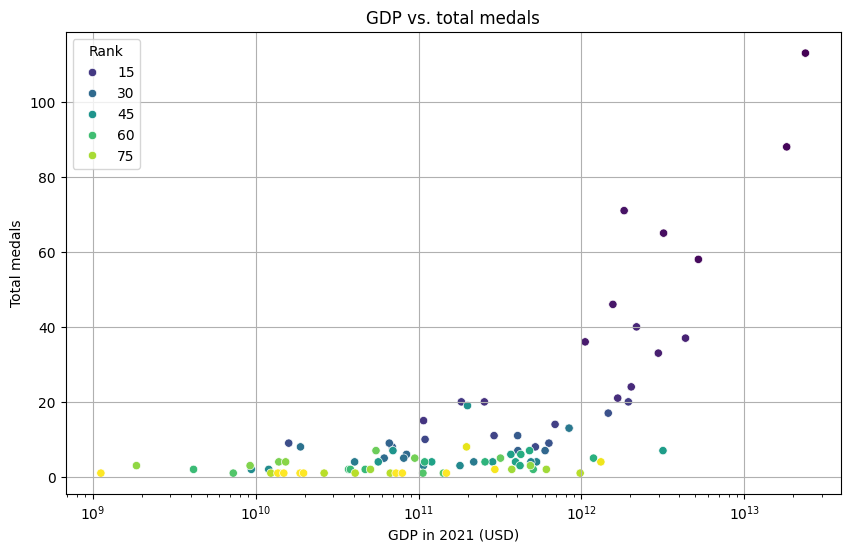

Correlation between GDP and total medals:
            GDP     Total
GDP    1.000000  0.829992
Total  0.829992  1.000000


In [16]:
# Correlation between GDP and total medals
GDP_YEAR = "2021"  # the Tokyo 2020 Games were held in 2021

medals_gdp_merged["GDP"] = medals_gdp_merged[GDP_YEAR]
correlation = medals_gdp_merged[["GDP", "Total"]].corr()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=medals_gdp_merged, x="GDP", y="Total", hue="Rank", palette="viridis")
plt.title("GDP vs. total medals")
plt.xlabel(f"GDP in {GDP_YEAR} (USD)")
plt.ylabel("Total medals")
plt.xscale("log")  # log scale because GDP differs by orders of magnitude
plt.grid(True)
plt.show()

print("Correlation between GDP and total medals:")
print(correlation)

**Result:** the correlation coefficient between GDP (2021, the year of the Games) and total medals is **0.830**, a strong positive relation: countries with a higher GDP tend to win more medals. GDP is shown on a log scale because it differs by orders of magnitude between countries.

## 2. Medal distribution by country

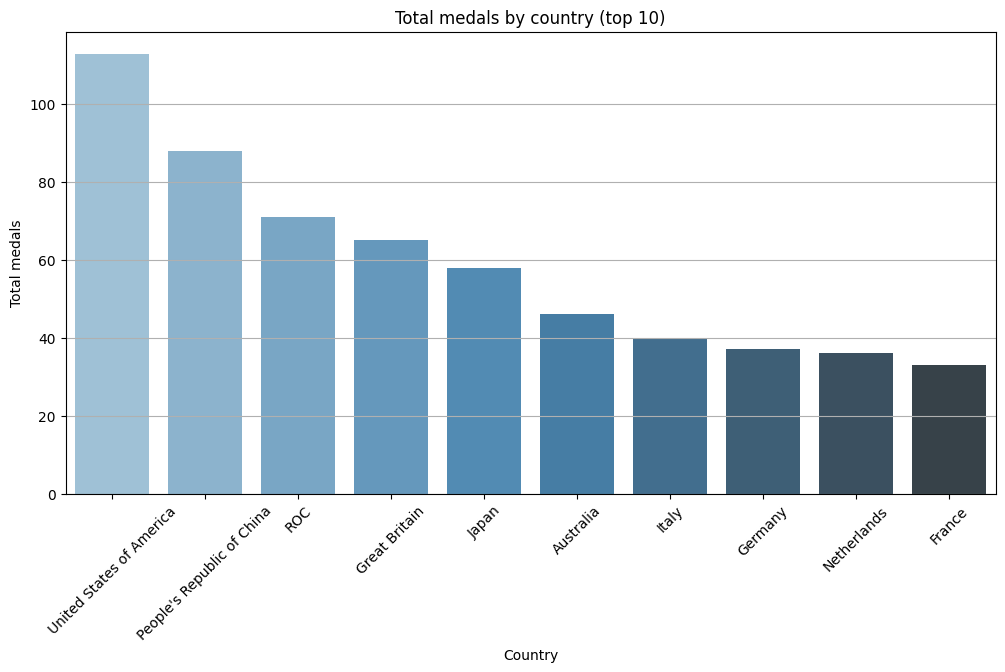

Top 10 countries by total medals:
Team/NOC
United States of America      113
People's Republic of China     88
ROC                            71
Great Britain                  65
Japan                          58
Australia                      46
Italy                          40
Germany                        37
Netherlands                    36
France                         33
Name: Total, dtype: int64


In [17]:
medals_distribution = medals.groupby("Team/NOC")["Total"].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=medals_distribution.index[:10],  # top 10 countries
    hue=medals_distribution.index[:10],
    legend=False,
    y=medals_distribution.values[:10],
    palette="Blues_d"
)
plt.title("Total medals by country (top 10)")
plt.xlabel("Country")
plt.ylabel("Total medals")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

print("Top 10 countries by total medals:")
print(medals_distribution.head(10))

## 3. Athletes and teams

- Number of athletes per team (bar plot, top 10)
- Distribution of athletes across disciplines (pie chart, top 10)

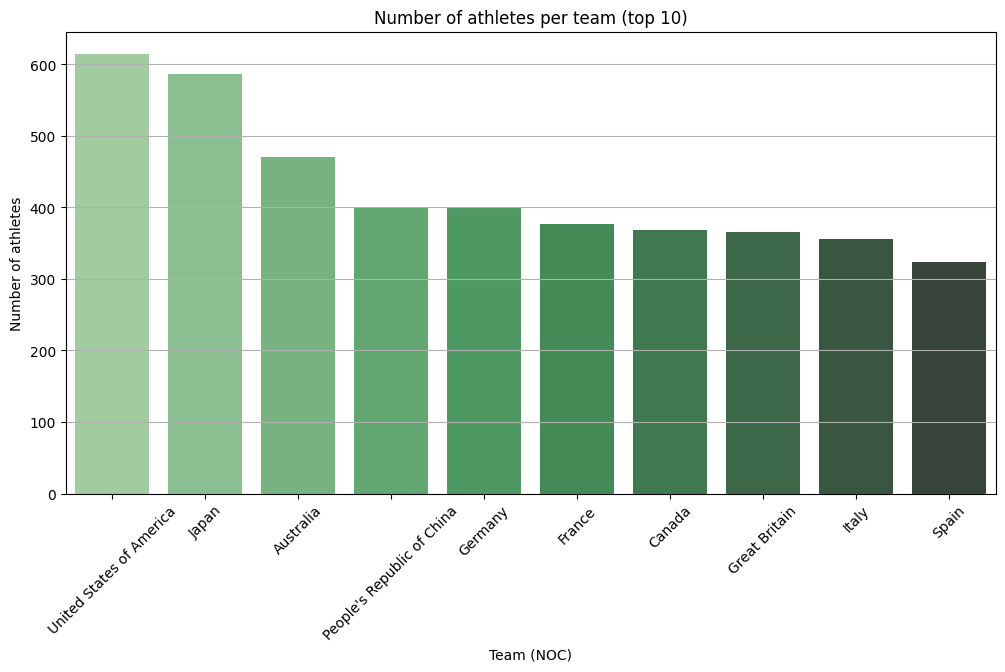

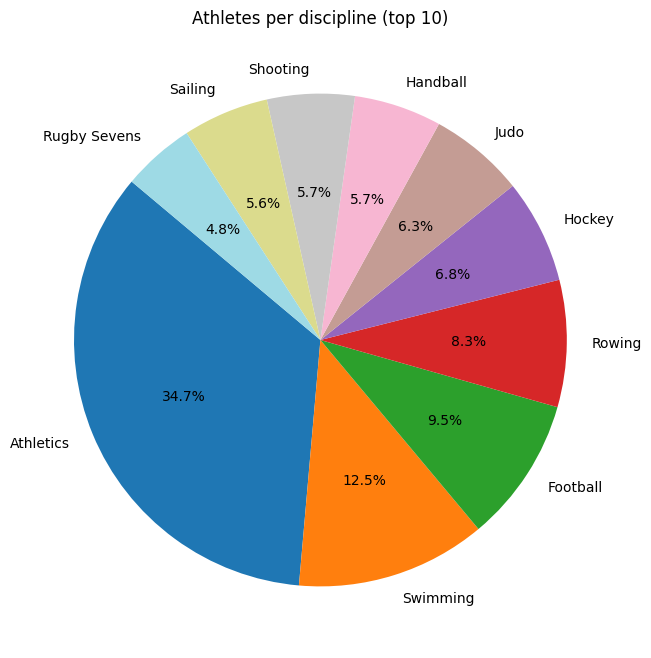

Top 10 teams by number of athletes:
NOC
United States of America      615
Japan                         586
Australia                     470
People's Republic of China    401
Germany                       400
France                        377
Canada                        368
Great Britain                 366
Italy                         356
Spain                         324
Name: Name, dtype: int64

Top 10 disciplines by number of athletes:
Discipline
Athletics       2068
Swimming         743
Football         567
Rowing           496
Hockey           406
Judo             373
Handball         342
Shooting         342
Sailing          336
Rugby Sevens     283
Name: Name, dtype: int64


In [18]:
# Number of athletes per team (NOC)
athletes_per_team = athletes.groupby("NOC")["Name"].count().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=athletes_per_team.index[:10],
    hue=athletes_per_team.index[:10],
    legend=False,
    y=athletes_per_team.values[:10],
    palette="Greens_d"
)
plt.title("Number of athletes per team (top 10)")
plt.xlabel("Team (NOC)")
plt.ylabel("Number of athletes")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

# Athletes per discipline
athletes_per_discipline = athletes.groupby("Discipline")["Name"].count().sort_values(ascending=False)

plt.figure(figsize=(8, 8))
athletes_per_discipline[:10].plot.pie(
    autopct='%1.1f%%', startangle=140, colormap="tab20", ylabel="",
    title="Athletes per discipline (top 10)"
)
plt.show()

print("Top 10 teams by number of athletes:")
print(athletes_per_team.head(10))

print("\nTop 10 disciplines by number of athletes:")
print(athletes_per_discipline.head(10))

# Regression

Predict the total number of medals from GDP and the number of athletes with multiple linear regression.

In [19]:
# Number of athletes per country
medals_gdp_merged["Athletes"] = medals_gdp_merged["Team/NOC"].map(
    athletes.groupby("NOC")["Name"].count()
)

print("Added column 'Athletes':")
print(medals_gdp_merged[["Team/NOC", "Athletes"]].head())

Added column 'Athletes':
                     Team/NOC  Athletes
0    United States of America       615
1  People's Republic of China       401
2                       Japan       586
3               Great Britain       366
4                         ROC       318


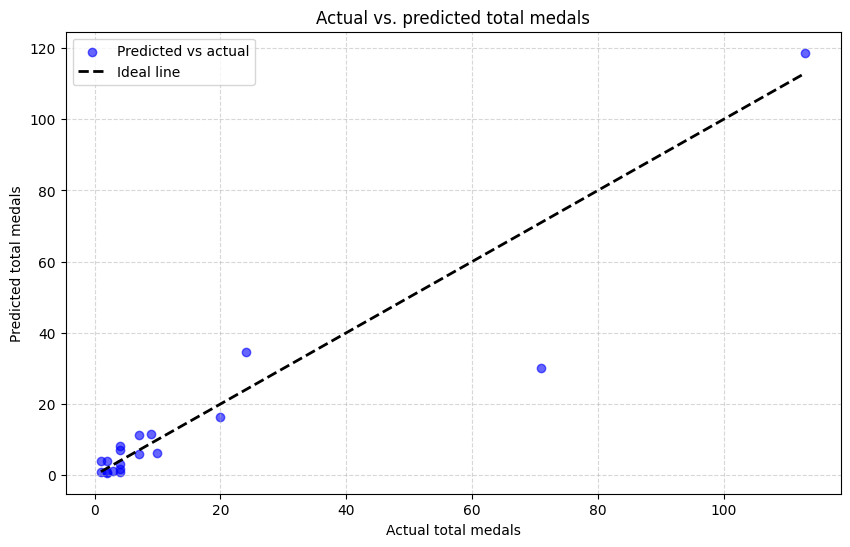

R^2: 0.8679540028500099
MSE: 102.02583349876026
Coefficients: [2.98871944e-12 7.81964902e-02]
Intercept: -0.305787825620488


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

regression_data = medals_gdp_merged[["GDP", "Athletes", "Total"]].dropna()

X = regression_data[["GDP", "Athletes"]]
y = regression_data["Total"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# GDP (~1e12) and athletes (~1e2) differ by ten orders of magnitude, which makes the
# unscaled least-squares fit numerically unstable, so the features are standardised first
model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
# Coefficients converted back to the original units (medals per USD, medals per athlete)
scaler = model.named_steps["standardscaler"]
linreg = model.named_steps["linearregression"]
coefficients = linreg.coef_ / scaler.scale_
intercept = linreg.intercept_ - np.sum(linreg.coef_ * scaler.mean_ / scaler.scale_)

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, label="Predicted vs actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label="Ideal line")
plt.title("Actual vs. predicted total medals")
plt.xlabel("Actual total medals")
plt.ylabel("Predicted total medals")
plt.legend()
plt.grid(alpha=0.5, linestyle="--")
plt.show()

print("R^2:", r2)
print("MSE:", mse)
print("Coefficients:", coefficients)
print("Intercept:", intercept)

**Results of the multiple linear regression:**

| | Value | Interpretation |
|---|---|---|
| GDP coefficient | ≈ 2.99e-12 | about 3 medals per additional 1,000 billion USD of GDP, at the same team size |
| Athletes coefficient | ≈ 0.078 | each additional athlete adds about 0.078 medals |
| Intercept | ≈ -0.31 | |
| R² (test set) | 0.868 | the model explains most of the variance |
| MSE (test set) | 102.03 | |

The number of athletes carries most of the predictive power; GDP adds little because it is strongly correlated with the team size. The features are standardised before fitting (GDP and the number of athletes differ by ten orders of magnitude) and the coefficients are converted back to the original units. The test set has only 19 countries, so R² should be read with care.

# Classification

Countries are split into four success classes by the quartiles of their total medals (Low, Medium, High, Very High), and a logistic regression predicts the class from GDP and the number of athletes.

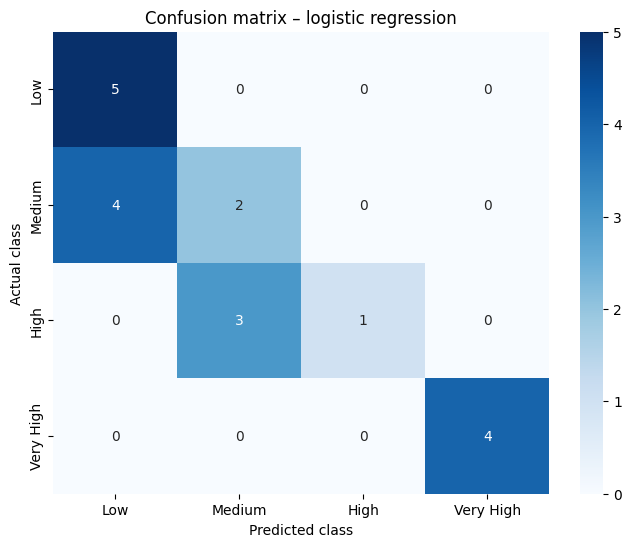

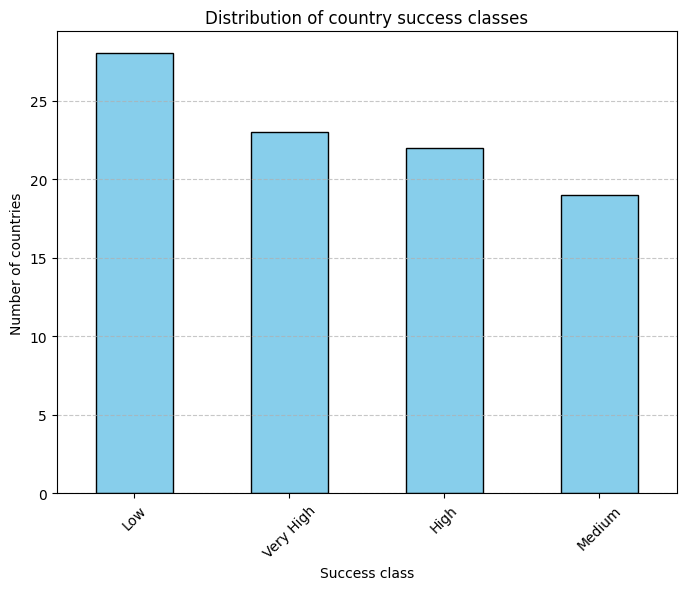

Classification report:
               precision    recall  f1-score   support

         Low       0.56      1.00      0.71         5
      Medium       0.40      0.33      0.36         6
        High       1.00      0.25      0.40         4
   Very High       1.00      1.00      1.00         4

    accuracy                           0.63        19
   macro avg       0.74      0.65      0.62        19
weighted avg       0.69      0.63      0.60        19



In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Success classes from the total number of medals (quartiles)
medals_gdp_merged["Success_Class"] = pd.qcut(
    medals_gdp_merged["Total"], q=4, labels=["Low", "Medium", "High", "Very High"]
)

# Encode the classes as numbers in their natural order (Low=0 ... Very High=3)
class_names = list(medals_gdp_merged["Success_Class"].cat.categories)
medals_gdp_merged["Success_Class_Label"] = medals_gdp_merged["Success_Class"].cat.codes

# Features and target
X_classification = medals_gdp_merged[["GDP", "Athletes"]]
y_classification = medals_gdp_merged["Success_Class_Label"]

# Train/test split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_classification, y_classification, test_size=0.2, random_state=42
)

# Logistic regression. GDP (~1e12) and the number of athletes (~1e2) are standardised
# first; without scaling the model predicts the same class for every country.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
)
logistic_model.fit(X_train_cls, y_train_cls)

# Predictions on the test set
y_pred_cls = logistic_model.predict(X_test_cls)

# Evaluation
classification_rep = classification_report(
    y_test_cls, y_pred_cls, labels=range(len(class_names)), target_names=class_names, zero_division=0
)
confusion_mat = confusion_matrix(y_test_cls, y_pred_cls, labels=range(len(class_names)))

# Confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix – logistic regression")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.show()

# Class distribution
class_distribution = medals_gdp_merged["Success_Class"].value_counts()
class_distribution.plot(kind='bar', figsize=(8, 6), color="skyblue", edgecolor="black")
plt.title("Distribution of country success classes")
plt.xlabel("Success class")
plt.ylabel("Number of countries")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

# Results
print("Classification report:\n", classification_rep)

**Results:** with standardised features and balanced class weights the model reaches an accuracy of **0.63** on the 19 test countries (macro F1 0.62). Without scaling it predicted "Very High" for every country (accuracy 0.21), because GDP (about 10¹²) and the number of athletes (about 10²) differ by ten orders of magnitude.

- **Very High** is recognised perfectly (precision and recall 1.00): the largest teams win the most medals.
- **Low** is always found (recall 1.00), but four countries from higher classes are also predicted as Low (precision 0.56).
- **Medium** and **High** are the hardest to separate (F1 0.36 and 0.40): countries in the middle of the medal table have similar GDP and team sizes.

With only 92 countries and 19 in the test set, the scores change noticeably with the split and should be read as indicative.

# Hypothesis testing

**Is there a statistically significant difference between the number of male and female athletes per discipline?**

- **Null hypothesis (H0):** there is no significant difference between the number of male and female athletes per discipline.
- **Alternative hypothesis (H1):** there is a significant difference.

A **t-test** compares the means of two groups:

- the *independent samples* t-test compares two separate groups,
- the *paired samples* t-test compares two measurements of the same units (here: men and women in the same discipline),
- the *one-sample* t-test compares one group with a fixed value.

Welch's independent t-test is used below; because every discipline has both a male and a female count, a paired test would be the stricter choice (see *Limitations*).

T-statistic: 0.29949672116231546
P-value: 0.7652624366726588
There is no statistically significant difference between the number of male and female competitors per discipline.


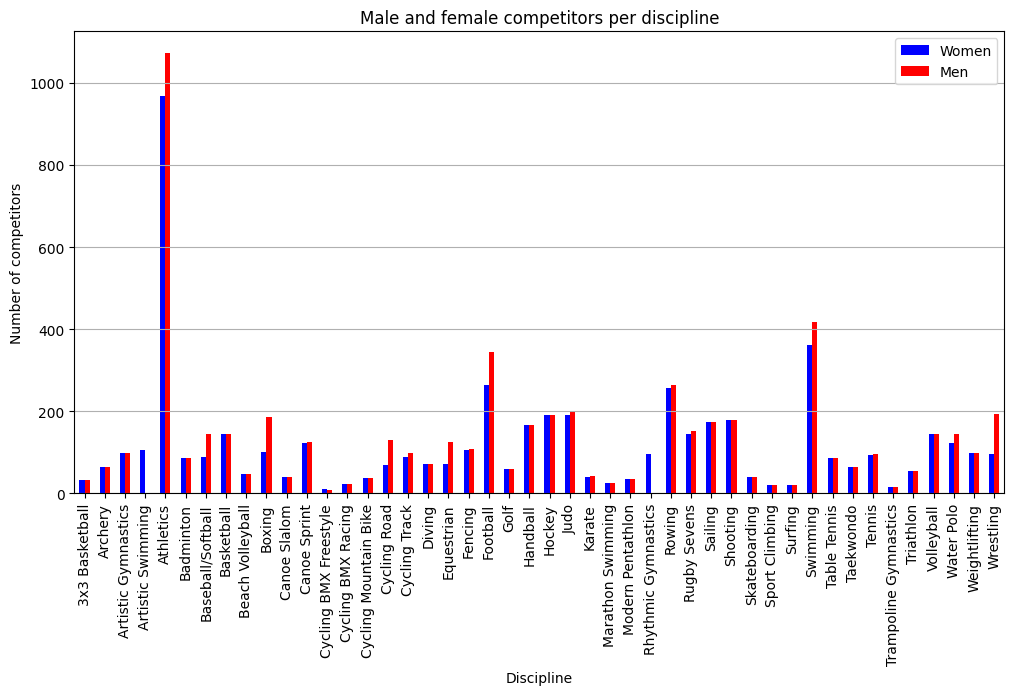

In [22]:
from scipy.stats import ttest_ind

# Total female and male competitors per discipline
gender_counts = entries_gender.groupby('Discipline')[['Female', 'Male']].sum()

t_stat, p_value = ttest_ind(gender_counts['Male'], gender_counts['Female'], equal_var=False)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("There is a statistically significant difference between the number of male and female competitors per discipline.")
else:
    print("There is no statistically significant difference between the number of male and female competitors per discipline.")

gender_counts.plot(kind='bar', figsize=(12, 6), color=['blue', 'red'])
plt.title('Male and female competitors per discipline')
plt.xlabel('Discipline')
plt.ylabel('Number of competitors')
plt.xticks(rotation=90)
plt.legend(['Women', 'Men'])
plt.grid(axis='y')
plt.show()

**Results:**

- **T-statistic: 0.2995**, close to zero: the average numbers of male and female competitors per discipline are very similar.
- **P-value: 0.7653**, far above α = 0.05, so the null hypothesis cannot be rejected.

**Conclusion:** at Tokyo 2020 men did not dominate in the number of competitors per discipline. The bar chart shows that individual disciplines differ, but across all disciplines the numbers are balanced, which reflects the IOC's gender-equality rules for these Games.

# Time-series analysis (1896–2016)

In [23]:
olympics = pd.read_csv(data_path("athlete_events.csv"))

In [24]:
olympics.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [25]:
def missing_values_analysis(df):
    na_columns_ = [col for col in df.columns if df[col].isnull().sum() > 0]
    n_miss = df[na_columns_].isnull().sum().sort_values(ascending=True)
    ratio_ = (df[na_columns_].isnull().sum() / df.shape[0] * 100).sort_values(ascending=True)
    missing_df = pd.concat([n_miss, np.round(ratio_, 2)], axis=1, keys=['Total Missing Values', 'Ratio'])
    missing_df = pd.DataFrame(missing_df)
    return missing_df

def check_df(df, head=5):
    print("--------------------- Shape --------------------")
    print(df.shape)
    print("-------------------- Types ---------------------")
    print(df.dtypes)
    print("----------------- NaN Analysis -----------------")
    print(missing_values_analysis(df))
    print("--------------------- Head ---------------------")
    print(df.head())

check_df(olympics)

--------------------- Shape --------------------
(271116, 15)
-------------------- Types ---------------------
ID          int64
Name       object
Sex        object
Age       float64
Height    float64
Weight    float64
Team       object
NOC        object
Games      object
Year        int64
Season     object
City       object
Sport      object
Event      object
Medal      object
dtype: object
----------------- NaN Analysis -----------------
        Total Missing Values  Ratio
Age                     9474   3.49
Height                 60171  22.19
Weight                 62875  23.19
Medal                 231333  85.33
--------------------- Head ---------------------
   ID                      Name Sex   Age  Height  Weight            Team  \
0   1                 A Dijiang   M  24.0   180.0    80.0           China   
1   2                  A Lamusi   M  23.0   170.0    60.0           China   
2   3       Gunnar Nielsen Aaby   M  24.0     NaN     NaN         Denmark   
3   4      Edgar Li

In [26]:
# Cleaning: remove duplicates and rows without age, height or weight
olympics.drop_duplicates(inplace=True)
olympics.dropna(subset=['Age', 'Height', 'Weight'], inplace=True)

# The Medal column is not needed here
if 'Medal' in olympics.columns:
    olympics.drop(columns=['Medal'], inplace=True)

check_df(olympics)
print("Rows after cleaning:", olympics.shape[0])
print("NaN values after cleaning:", olympics.isnull().sum().sum())

--------------------- Shape --------------------
(206152, 14)
-------------------- Types ---------------------
ID          int64
Name       object
Sex        object
Age       float64
Height    float64
Weight    float64
Team       object
NOC        object
Games      object
Year        int64
Season     object
City       object
Sport      object
Event      object
dtype: object
----------------- NaN Analysis -----------------
Empty DataFrame
Columns: [Total Missing Values, Ratio]
Index: []
--------------------- Head ---------------------
   ID                      Name Sex   Age  Height  Weight         Team  NOC  \
0   1                 A Dijiang   M  24.0   180.0    80.0        China  CHN   
1   2                  A Lamusi   M  23.0   170.0    60.0        China  CHN   
4   5  Christine Jacoba Aaftink   F  21.0   185.0    82.0  Netherlands  NED   
5   5  Christine Jacoba Aaftink   F  21.0   185.0    82.0  Netherlands  NED   
6   5  Christine Jacoba Aaftink   F  25.0   185.0    82.0  Nether

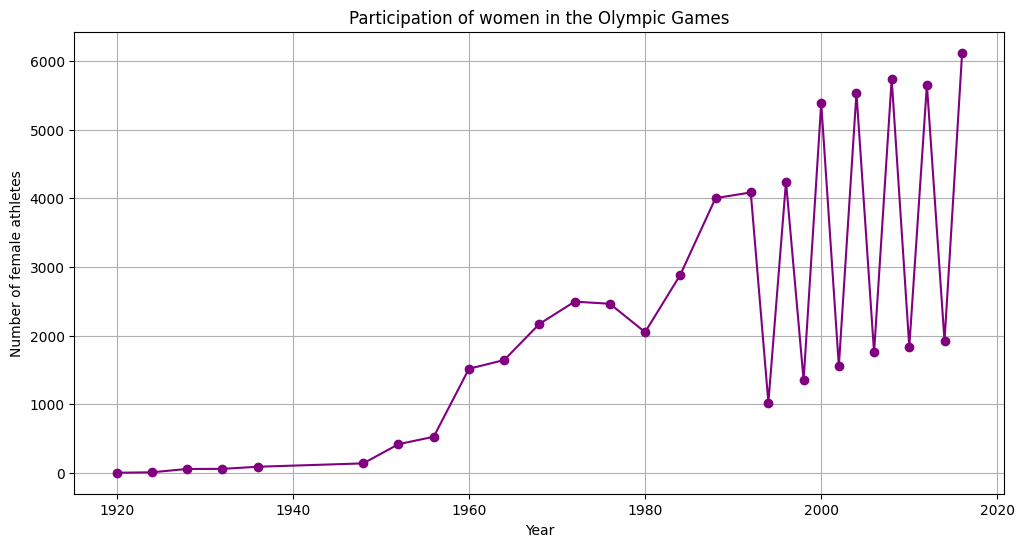

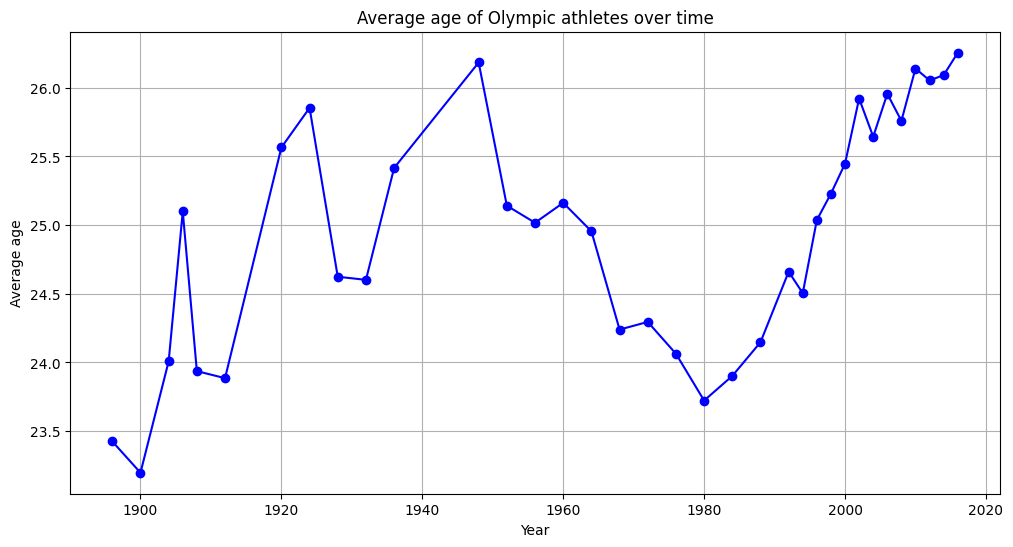

Year
1920     1
1924     7
1928    56
1932    57
1936    88
dtype: int64
Year
1896    23.425000
1900    23.197183
1904    24.008403
1906    25.099502
1908    23.936986
Name: Age, dtype: float64


In [27]:
# Number of female athletes per Games
women_participation = olympics[olympics['Sex'] == 'F'].groupby('Year').size()

plt.figure(figsize=(12, 6))
plt.plot(women_participation.index, women_participation.values, marker='o', linestyle='-', color='purple')
plt.xlabel('Year')
plt.ylabel('Number of female athletes')
plt.title('Participation of women in the Olympic Games')
plt.grid(True)
plt.show()

# Average athlete age per Games
average_age = olympics.groupby('Year')['Age'].mean()

plt.figure(figsize=(12, 6))
plt.plot(average_age.index, average_age.values, marker='o', linestyle='-', color='blue')
plt.xlabel('Year')
plt.ylabel('Average age')
plt.title('Average age of Olympic athletes over time')
plt.grid(True)
plt.show()

print(women_participation.head())
print(average_age.head())

**1. Participation of women**

- The number of female athletes grew strongly over time. It stayed low until the 1950s, jumped in 1960 (from 525 to 1,516) and kept rising to about 6,100 in 2016, in line with global efforts for gender equality in sport.
- The zig-zag pattern from 1994 onwards comes from the alternating Summer and Winter Games, which have been held in different years since then (the Winter Games are much smaller).

**2. Average age**

- The average age fell from about 26 years in 1948 to its lowest point around 1980 (23.7 years) and has risen since then to 26.3 years in 2016.
- Better training, sports medicine and rehabilitation allow longer careers.

Note: rows without height or weight were removed, which drops many early Games; the early years are therefore less representative (for example, women appear only from 1920, although they first competed in 1900).

# Question answering with an LLM (retrieval-augmented generation)

The assistant first **retrieves** facts from the project's own data: if the question mentions a Tokyo 2020 participant country, its row from `Medals.xlsx` (rank and gold/silver/bronze/total) is added to the prompt. The **generation** step then asks Gemini to answer, using the retrieved data when it is relevant. Without matching data the model answers from its own knowledge, which can contain mistakes.

Set the API key as the `GOOGLE_API_KEY` Colab secret or environment variable. **Never write the key into the notebook.**

In [33]:
# In Colab, pip may print a dependency notice about google-auth; it does not affect this notebook
%pip install -q -U google-genai

In [29]:
import os
from google import genai

GEMINI_MODEL = "gemini-3.6-flash"  # check https://ai.google.dev/models for current model names

try:
    from google.colab import userdata
    api_key = userdata.get('GOOGLE_API_KEY')
except ImportError:
    api_key = os.environ.get('GOOGLE_API_KEY')

client = genai.Client(api_key=api_key)

In [30]:
def retrieve_medal_context(question):
    """Return the Tokyo 2020 medal rows of the countries mentioned in the question."""
    q = question.lower()
    rows = medals[medals["Team/NOC"].str.lower().apply(lambda country: country in q)]
    if rows.empty:
        return ""
    return rows[["Rank", "Team/NOC", "Gold", "Silver", "Bronze", "Total"]].to_string(index=False)


def answer_question(question):
    context = retrieve_medal_context(question)
    prompt = (
        "You are an expert on the Olympic Games. Answer the question precisely and briefly.\n"
        + (f"Use this Tokyo 2020 medal table data if it is relevant:\n{context}\n" if context else "")
        + f"Question: {question}"
    )
    try:
        response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt)
        return response.text
    except Exception as e:
        return f"The answer could not be generated ({e})."


def question_session():
    print("Ask questions about the Olympic Games. Type 'exit' to stop.")
    while True:
        question = input("Question: ")
        if question.lower() == 'exit':
            print("Goodbye!")
            break
        print(f"\nAnswer: {answer_question(question)}\n")


question_session()

Ask questions about the Olympic Games. Type 'exit' to stop.
Question: At the Tokyo 2020 Olympic Games, the USA won the highest total number of medals (113).

Answer: Correct. The United States won the highest total number of medals at the Tokyo 2020 Olympic Games with 113 (39 gold, 41 silver, and 33 bronze).

Question: At the 2020 Tokyo Olympics, China won the most gold medals.

Answer: Incorrect. The United States won the most gold medals at the 2020 Tokyo Olympics with 39, edging out China, which won 38.

Question: Croatia won 8 medals at the Tokyo 2020 Games: 3 gold, 3 silver, and 2 bronze.

Answer: That is correct.

Question: At Tokyo 2020, football had more competitors than swimming.

Answer: **False.** 

Swimming had significantly more competitors than football at the Tokyo 2020 Olympics. Swimming had approximately **930 athletes**, whereas football (soccer) had roughly **600 athletes** across the men's and women's tournaments.

Question: Rhythmic gymnastics and artistic swimming

# Web scraping: an Olympic quiz

Facts about the Olympic Games are scraped with `requests` and BeautifulSoup from three Croatian- and Bosnian-language pages, filtered, and turned into true/false questions. A false variant is created by replacing "most" (*najviše*) with "least" (*najmanje*). The facts stay in their original language. The questions are asked in rounds of 10 until all have been asked. If no page can be scraped, the quiz uses the offline test questions defined below.

Sources: [hrsport.hr](https://hrsport.hr/zanimljivosti-o-olimpijskim-igrama-top-60/), [ahaslides.com](https://ahaslides.com/hr/blog/olympics-quiz/), [novostiplus.org](https://www.novostiplus.org/bs/zanimljivosti-o-olimpijskim-igrama-za-koje-sigurno-niste-culi-fascinantne-24-cinjenice-iz-istorije-oi/).

**Offline test questions.** If the pages cannot be scraped (no internet, a changed page layout), the quiz uses the test questions below. Every statement was checked against the project's own data: `Medals.xlsx`, `Athletes.xlsx` and `EntriesGender.xlsx` for Tokyo 2020, and `athlete_events.csv` for Olympic history up to 2016. About half of the statements are false. To play only these questions, run `start_quiz(TEST_QUESTIONS)`.

In [31]:
# Offline test questions, checked against the project datasets
TEST_QUESTIONS = [
    {"question": "True or false? In Tokyo 2020, the USA won the most medals in total (113).", "answer": "true"},
    {"question": "True or false? In Tokyo 2020, China won the most gold medals.", "answer": "false"},
    {"question": "True or false? Japan won 27 gold medals in Tokyo 2020 and finished third in the medal table.", "answer": "true"},
    {"question": "True or false? Croatia won 8 medals in Tokyo 2020: 3 gold, 3 silver and 2 bronze.", "answer": "true"},
    {"question": "True or false? Croatia won more medals than Serbia in Tokyo 2020.", "answer": "false"},
    {"question": "True or false? In Tokyo 2020, the ROC won more medals in total than Great Britain, but fewer gold medals.", "answer": "true"},
    {"question": "True or false? Kosovo won two gold medals in Tokyo 2020.", "answer": "true"},
    {"question": "True or false? More than 120 countries won at least one medal in Tokyo 2020.", "answer": "false"},
    {"question": "True or false? Athletics was the discipline with the most competitors in Tokyo 2020.", "answer": "true"},
    {"question": "True or false? More women than men competed in Tokyo 2020.", "answer": "false"},
    {"question": "True or false? In Tokyo 2020, football had more competitors than swimming.", "answer": "false"},
    {"question": "True or false? In Tokyo 2020, rhythmic gymnastics and artistic swimming had only female competitors.", "answer": "true"},
    {"question": "True or false? In Tokyo 2020, wrestling had more female than male competitors.", "answer": "false"},
    {"question": "True or false? The first modern Olympic Games were held in Athens in 1896.", "answer": "true"},
    {"question": "True or false? The first Winter Olympic Games were held in 1936.", "answer": "false"},
    {"question": "True or false? Women first competed at the Olympic Games in 1900.", "answer": "true"},
    {"question": "True or false? By 2016, Michael Phelps had won 23 Olympic gold medals, the most in history.", "answer": "true"},
    {"question": "True or false? Croatia first competed at the Olympic Games as an independent country in 1996.", "answer": "false"},
    {"question": "True or false? London has hosted the Summer Olympic Games only twice.", "answer": "false"},
    {"question": "True or false? More than 11,000 athletes competed at the 2016 Olympic Games in Rio de Janeiro.", "answer": "true"},
]

print(f"{len(TEST_QUESTIONS)} test questions, "
      f"{sum(q['answer'] == 'false' for q in TEST_QUESTIONS)} of them false.")

20 test questions, 9 of them false.


In [32]:
import random
import requests
from bs4 import BeautifulSoup

# Croatian keywords used to keep relevant facts and drop navigation text
OLYMPIC_KEYWORDS = ["olimpijske", "igre", "medalje", "sport", "natjecanje", "plamen", "prstenovi", "rekordi", "atletika"]
NOISE_KEYWORDS = ["kolo", "kviz", "blog", "kategorije", "tutorial", "hotel"]
QUESTION_KEYWORDS = ["održane", "osvojila", "prvi put", "godine", "medalje", "natjecanje", "rekordi"]


def scrape_olympics_facts(url):
    """Scrape facts about the Olympic Games from the given page."""
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, 'html.parser')

        facts = []
        if "ahaslides" in url:
            for li in soup.find_all('li'):
                text = li.text.strip()
                if len(text) > 15 and all(k not in text.lower() for k in NOISE_KEYWORDS):
                    facts.append(text)
        else:
            for li in soup.find_all('li'):
                fact = li.text.strip()
                if len(fact) > 15 and any(k in fact.lower() for k in OLYMPIC_KEYWORDS):
                    facts.append(fact)

        # Drop headings and other short or irrelevant items
        return [
            fact for fact in facts
            if len(fact.split()) > 3
            and not fact.lower().startswith("napredni")
            and not any(k in fact.lower() for k in NOISE_KEYWORDS)
        ]
    except Exception as e:
        print(f"Scraping failed for {url}: {e}")
        return []


def generate_questions(facts, used_questions):
    """Create true/false questions from the facts."""
    questions = []
    for fact in facts:
        if fact in used_questions:
            continue
        if any(k in fact.lower() for k in QUESTION_KEYWORDS):
            questions.append({"question": f"True or false? {fact}", "answer": "true"})
            used_questions.add(fact)

        if "najviše" in fact:  # "most" -> "least" makes a false statement
            fake_fact = fact.replace("najviše", "najmanje")
            if fake_fact not in used_questions:
                questions.append({"question": f"True or false? {fake_fact}", "answer": "false"})
                used_questions.add(fake_fact)
    return questions


def start_quiz(question_pool, rounds_of=10):
    """Ask the questions in rounds of `rounds_of`; every question is asked once."""
    print("Olympic Games quiz! Answer 'true', 'false' or 'exit'.")
    pool = list(question_pool)
    random.shuffle(pool)

    while pool:
        questions, pool = pool[:rounds_of], pool[rounds_of:]
        score = 0
        for i, q in enumerate(questions, start=1):
            print(f"Question {i}: {q['question']}")
            answer = input("Your answer (true/false): ").strip().lower()
            while answer not in ("true", "false", "exit"):
                answer = input("Please type 'true', 'false' or 'exit': ").strip().lower()
            if answer == "exit":
                print("Thanks for playing!")
                return
            if answer == q["answer"]:
                print("Correct!\n")
                score += 1
            else:
                print(f"Wrong! The statement is {q['answer']}.\n")
        print(f"Your score: {score}/{len(questions)}\n")
    print("No more questions. Thanks for playing!")


urls = [
    "https://hrsport.hr/zanimljivosti-o-olimpijskim-igrama-top-60/",
    "https://ahaslides.com/hr/blog/olympics-quiz/",
    "https://www.novostiplus.org/bs/zanimljivosti-o-olimpijskim-igrama-za-koje-sigurno-niste-culi-fascinantne-24-cinjenice-iz-istorije-oi/",
]

all_facts = [fact for url in urls for fact in scrape_olympics_facts(url)]
scraped_questions = generate_questions(all_facts, set())

# Web questions when scraping works, otherwise the offline test questions
if scraped_questions:
    start_quiz(scraped_questions)
else:
    print("Could not fetch any facts, using the offline test questions.\n")
    start_quiz(TEST_QUESTIONS)


Olympic Games quiz! Answer 'true', 'false' or 'exit'.
Question 1: True or false? Olimpijske igre u Sydneyu 2000. godine bile su prve Igre u novom tisućljeću.
Your answer (true/false): true
Correct!

Question 2: True or false? Najmlađi osvajač zlatne medalje bila je američka gimnastičarka Marjorie Gestring, koja je imala samo 13 godina kada je pobijedila u skokovima u vodu 1936. godine.
Your answer (true/false): true
Correct!

Question 3: True or false? Najstariji osvajač olimpijske medalje bio je švedski strijelac Oscar Swahn, koji je imao 72 godine kada je osvojio srebrnu medalju 1920. godine.
Your answer (true/false): false
Wrong! The statement is true.

Question 4: True or false? Olimpijske igre u Riju 2016. bile su prve Igre održane u Južnoj Americi.
Your answer (true/false): false
Wrong! The statement is true.

Question 5: True or false? Najveća olimpijska ekipa ikad bila je američka ekipa sa 761 sportašem na Igrama u Atlanti 1996. godine.
Your answer (true/false): true
Correct!



# Limitations

- **Country names.** Medals and GDP are merged on country names through a hand-made mapping (`COUNTRY_NAME_MAP`). *Chinese Taipei* has no World Bank GDP row and is left out. Merging on ISO country codes would be more robust.
- **GDP gaps** remaining after interpolation are filled with the mean of all countries, which overestimates the GDP of small economies.
- **Small samples.** The regression and classification test sets contain 19 countries.
- **Hypothesis test.** Male and female counts come from the same disciplines, so a paired test (`scipy.stats.ttest_rel` or Wilcoxon) is the more appropriate test.
- **LLM answers** without retrieved data come from the model's own knowledge and can be wrong.
- **Quiz facts.** Every scraped fact is treated as true, and the page filter can still let an unrelated item through. The offline test questions were checked against the datasets.